Результаты оценки регрессионной модели DecisionTreeRegressor:
MSE (Среднеквадратическая ошибка): 0.0111
RMSE (Корень из MSE): 0.1052
MAE (Средняя абсолютная ошибка): 0.0778


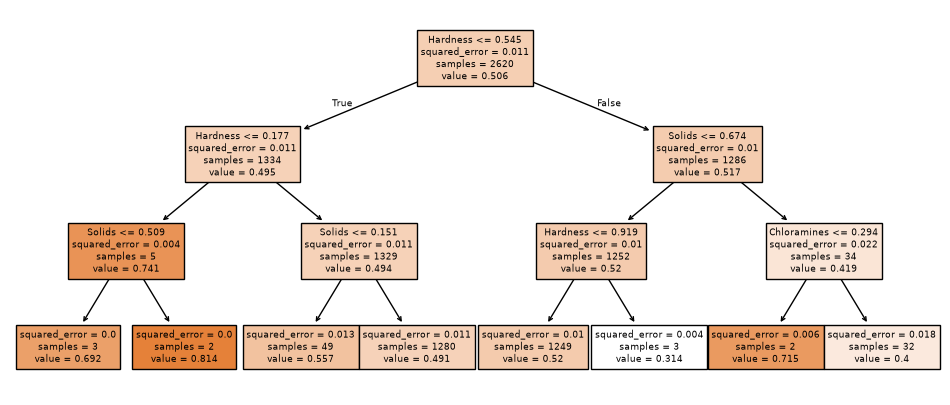

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import tree
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

# Загрузка и подготовка данных
df = pd.read_csv('water_potability_final4.csv')
X = df.drop(columns=['ph', 'Potability'])
y = df['ph']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Обучение модели
dt_regressor = DecisionTreeRegressor(max_depth=3, random_state=42)
dt_regressor.fit(X_train, y_train)

# Предсказание и оценка
y_pred = dt_regressor.predict(X_test)
print('Результаты оценки регрессионной модели DecisionTreeRegressor:')
print(f'MSE (среднеквадратичная ошибка): {mean_squared_error(y_test, y_pred):.4f}')
print(f'RMSE )(корень из mse): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}')
print(f'MAE (средняя абс ошибка): {mean_absolute_error(y_test, y_pred):.4f}')

# Визуализация дерева
plt.figure(figsize=(12, 5))
tree.plot_tree(dt_regressor, filled=True, feature_names=X.columns)
plt.show()

print(і := f"Результаты оценки регрессионной модели DecisionTreeRegressor:")
print(f"MSE (Среднеквадратическая ошибка): {mse:.4f}")
print(f"RMSE (Корень из MSE): {rmse:.4f}")
print(f"MAE (Средняя абсолютная ошибка): {mae:.4f}")

from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
tree.plot_tree(dt_regressor, filled=True, feature_names=X.columns)
plt.show()

Метрика ROC-AUC: 0.6043


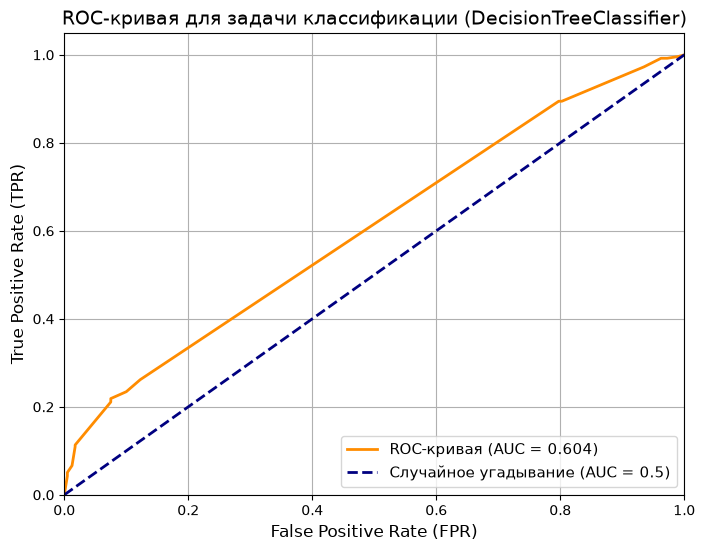

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, auc

# 1. Выделяем признаки и целевую переменную для классификации
X_cls = df.drop(columns=['Potability'])
y_cls = df['Potability']

# 2. Делим выборку на обучающую и тестовую с сохранением пропорций
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)

# 3. Создаем и обучаем модель классификации
dt_classifier = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_classifier.fit(X_train_cls, y_train_cls)

# 4. Получаем вероятности классов
y_proba = dt_classifier.predict_proba(X_test_cls)

# 5. Считаем координаты ROC-кривой и метрику AUC[cite: 2]
fpr, tpr, thresholds = roc_curve(y_test_cls, y_proba[:, 1])
roc_auc = auc(fpr, tpr)

# Обязательный вывод текста, чтобы увидеть результат в ноутбуке:
print(f"Метрика ROC-AUC: {roc_auc:.4f}")

# 6. Визуализация ROC-кривой[cite: 2]
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC-кривая (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Случайное угадывание (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('ROC-кривая для задачи классификации (DecisionTreeClassifier)', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True)
plt.show()